In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 4 — Challenge A: classification tree (R2)

**Scope:** P4.1, P4.2, the importances of P4.4 and the cyber part of P4.5.

We use the fitted-tree methods from the Topic 8 notebook and follow the official
Practice 4 handout for selection and evaluation. All results use the course's
canonical folds. Choosing `criterion="entropy"` changes the split criterion, but
the scikit-learn model is still a binary tree, not ID3 or C4.5.

## Setup from R1 and R4

These cells make this role notebook runnable on its own. R5 should use the shared
setup once when joining the final cyber notebook.

- R1 cyber data and preprocessor: `r1-datos`, commit `4ba34ab3`.
- Canonical-fold and metric code adapted from R4: `r4-evaluacion`, commit `8b05b047`.
- No other role's files are changed.

In [2]:
import json
import time
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, validation_curve
from sklearn import metrics

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)

CYBER_DIR = "../datos/cyber"
FOLDS_DIR = "../folds"

Python: 3.14.6
NumPy: 2.4.6
pandas: 3.0.3
scikit-learn: 1.9.0
matplotlib: 3.11.0


In [3]:
# Load the tables and the class codes without modifying the original files.
dev = pd.read_csv(CYBER_DIR + "/cyber_development.csv")
cyber_groups = pd.read_csv(CYBER_DIR + "/cyber_groups.csv")
cyber_folds = pd.read_csv(FOLDS_DIR + "/cyber_folds.csv")

# The JSON keys are text; convert them to the integer codes used in y.
with open(CYBER_DIR + "/cyber_class_codes.json", encoding="utf-8") as file:
    class_codes = json.load(file)

CLASS_NAMES = {}
for code, name in class_codes.items():
    CLASS_NAMES[int(code)] = name

# The 11 source predictors of P2. Metadata columns are never predictors.
NOMINAL = ["proto", "service", "conn_state"]
NUMERIC = ["duration", "src_bytes", "dst_bytes", "missed_bytes",
           "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]
FEATURES = NOMINAL + NUMERIC

expected_columns = ["row_id"] + FEATURES + ["attack_code"]
assert list(dev.columns) == expected_columns, "Unexpected cyber schema"

X = dev[FEATURES].copy()
y = dev["attack_code"].copy()
for column in ["row_id", "feature_group", "config_group", "fold_id", "attack_code"]:
    assert column not in X.columns, "Forbidden predictor: " + column

assert X.shape[1] == 11, "Expected 11 source predictors"
assert not dev.isna().any().any(), "Missing values in development data"
assert np.isfinite(X[NUMERIC].to_numpy()).all(), "Non-finite numeric predictors"
assert pd.api.types.is_integer_dtype(y), "Class codes must be integers"
assert sorted(y.unique()) == sorted(CLASS_NAMES), "Class codes do not match JSON"

print("Development table:", dev.shape)
print("Predictors:", X.shape, "(", len(NOMINAL), "nominal and", len(NUMERIC), "numeric )")
print("Class names:", CLASS_NAMES)

Development table: (34928, 13)
Predictors: (34928, 11) ( 3 nominal and 8 numeric )
Class names: {0: 'backdoor', 1: 'ddos', 2: 'dos', 3: 'injection', 4: 'mitm', 5: 'normal', 6: 'password', 7: 'ransomware', 8: 'scanning', 9: 'xss'}


In [4]:
# R4's canonical-fold block, with the group and coverage checks kept explicit.
fold_table = pd.read_csv(FOLDS_DIR + "/cyber_folds.csv")
groups = cyber_groups
assert dev["row_id"].is_unique
assert dev["row_id"].equals(fold_table["row_id"])
assert dev["row_id"].equals(groups["row_id"])
fold_ids = fold_table["fold_id"].to_numpy()
assert sorted(np.unique(fold_ids)) == [0, 1, 2, 3, 4]

folds = []
fold_rows = []
coverage = np.zeros(len(dev), dtype=int)
for f in range(5):
    train_idx = np.where(fold_ids != f)[0]
    val_idx = np.where(fold_ids == f)[0]
    train_groups = set(groups.iloc[train_idx]["feature_group"])
    val_groups = set(groups.iloc[val_idx]["feature_group"])
    assert train_groups.isdisjoint(val_groups)
    assert len(train_idx) + len(val_idx) == len(dev)
    assert sorted(y.iloc[train_idx].unique()) == sorted(CLASS_NAMES)
    folds.append((train_idx, val_idx))
    coverage[val_idx] = coverage[val_idx] + 1
    fold_rows.append({"fold": f, "train_rows": len(train_idx),
                      "validation_rows": len(val_idx)})

assert (coverage == 1).all()
print(pd.DataFrame(fold_rows).to_string(index=False))
print("Feature groups:", groups["feature_group"].nunique())
print("No shared groups; every row is validated once.")

 fold  train_rows  validation_rows
    0       27942             6986
    1       27942             6986
    2       27943             6985
    3       27942             6986
    4       27943             6985
Feature groups: 34883
No shared groups; every row is validated once.


In [5]:
def make_preprocessor():
    # One-hot with every level kept: a tree needs no reference level.
    # "ignore" encodes a level unseen in training as all zeros.
    nominal_steps = OneHotEncoder(drop=None, handle_unknown="ignore", sparse_output=False)

    # Numeric predictors pass through unchanged: no log1p and no scaler.
    preprocessor = ColumnTransformer([
        ("cat", nominal_steps, NOMINAL),
        ("num", "passthrough", NUMERIC),
    ])
    # Returned unfitted so that R2 puts it inside its Pipeline.
    return preprocessor

**Representation.** We use R1's preprocessor: full one-hot encoding for
nominal predictors and unchanged numeric columns. There is no scaler or `log1p`.
A tree splits one predictor at a time using a threshold, so standardising it does
not add useful split options. Keeping the original units also makes the thresholds
easier to read. Small numerical differences can still occur in a library fit.

**Mapping from P3 to P4.** P3 dropped `proto=tcp`, `service=-` and `conn_state=SF`.
For each predictor, an all-zero indicator block represented its dropped level.
P4 keeps the columns `proto_tcp`, `service_-` and `conn_state_SF`, as well as the
other level columns. The retained indicators have the same meaning: one means
the row has that level, and zero means it does not. Numeric columns also change
from P3's standardised `log1p` values to their original values in P4.

With `handle_unknown="ignore"`, an unseen level produces an all-zero block. Since
P4 keeps every training level, this means none of the known levels, rather than
a reference level. The encoder is fitted inside each fold's pipeline, so its
vocabulary comes only from training rows.

In [6]:
# Short checks of R1's representation on each fold.
representation_rows = []
for f, (train_idx, val_idx) in enumerate(folds):
    prep = make_preprocessor()
    train_t = prep.fit_transform(X.iloc[train_idx])
    val_t = prep.transform(X.iloc[val_idx])
    encoder = prep.named_transformers_["cat"]
    assert encoder.drop_idx_ is None
    n_cat = train_t.shape[1] - len(NUMERIC)
    assert train_t.shape[1] == val_t.shape[1]
    assert np.array_equal(train_t[:, n_cat:], X.iloc[train_idx][NUMERIC])
    assert np.array_equal(val_t[:, n_cat:], X.iloc[val_idx][NUMERIC])
    unseen = 0
    for column, levels in zip(NOMINAL, encoder.categories_):
        unseen = unseen + int((~X.iloc[val_idx][column].isin(levels)).sum())
    representation_rows.append({"fold": f, "transformed_columns": train_t.shape[1],
                                "unseen_nominal_values": unseen})
print(pd.DataFrame(representation_rows).to_string(index=False))

def spread(values):
    return np.max(values) - np.min(values)

def cyber_metrics(y_true, y_pred):
    macro_f1 = metrics.f1_score(y_true, y_pred, average="macro")
    weighted_f1 = metrics.f1_score(y_true, y_pred, average="weighted")
    accuracy = metrics.accuracy_score(y_true, y_pred)
    return [macro_f1, weighted_f1, accuracy]

 fold  transformed_columns  unseen_nominal_values
    0                   33                      0
    1                   33                      0
    2                   33                      0
    3                   32                      1
    4                   33                      0


# P4.1 — Tree classification

In [7]:
def make_tree():
    return Pipeline([
        ("preprocessing", make_preprocessor()),
        ("tree", DecisionTreeClassifier(random_state=PROJECT_RANDOM_STATE)),
    ])

param_grid = {
    "tree__max_depth": [3, 5, 8, 12, 20, None],
    "tree__min_samples_leaf": [1, 5, 20, 50],
    "tree__ccp_alpha": [0.0, 1e-5, 1e-4, 1e-3],
    "tree__criterion": ["gini", "entropy"],
}
n_candidates = 1
for values in param_grid.values():
    n_candidates = n_candidates * len(values)
print("Declared grid:", param_grid)
print("Candidates:", n_candidates)
print("Cross-validation fits:", n_candidates * len(folds))

Declared grid: {'tree__max_depth': [3, 5, 8, 12, 20, None], 'tree__min_samples_leaf': [1, 5, 20, 50], 'tree__ccp_alpha': [0.0, 1e-05, 0.0001, 0.001], 'tree__criterion': ['gini', 'entropy']}
Candidates: 192
Cross-validation fits: 960


**Declared grid and why.** We try shallow and deeper trees, including
unlimited depth, to see whether extra splits help validation. The minimum leaf
sizes range from individual rows to larger leaves, which can reduce overfitting.
An alpha of zero means no pruning; the positive values try increasing amounts of
pruning. We also compare Gini and entropy. Their impurity scales differ, so the
same alpha does not necessarily prune them equally.

We select the configuration with the highest mean validation macro F1 on the
canonical folds. The seed stays fixed, and an exact score tie is resolved by the
search order. As required by the handout, we use these same folds for selection
and reporting, without an extra holdout. This can make the selected score
optimistic, so it should not be treated as an independent test result.

In [8]:
search = GridSearchCV(
    make_tree(),
    param_grid,
    cv=folds,
    scoring="f1_macro",
    return_train_score=True,
    n_jobs=4,
    error_score="raise",
)
start = time.perf_counter()
search.fit(X, y)
search_seconds = time.perf_counter() - start
print("Search time including final refit (s):", round(search_seconds, 3))

Search time including final refit (s): 53.611


In [9]:
best = search.best_params_
best_index = search.best_index_
for parameter in param_grid:
    print(parameter, "=", best[parameter], "| tried:", param_grid[parameter])
print("Selected mean validation macro F1:", round(search.best_score_, 6))

grid_results = pd.DataFrame(search.cv_results_)

tree__max_depth = 20 | tried: [3, 5, 8, 12, 20, None]
tree__min_samples_leaf = 1 | tried: [1, 5, 20, 50]
tree__ccp_alpha = 0.0001 | tried: [0.0, 1e-05, 0.0001, 0.001]
tree__criterion = entropy | tried: ['gini', 'entropy']
Selected mean validation macro F1: 0.945742


In [10]:
# GridSearchCV refits the winner on all development rows.
final_pipe = search.best_estimator_
final_tree = final_pipe.named_steps["tree"]
feature_names = final_pipe.named_steps["preprocessing"].get_feature_names_out()
t = final_tree.tree_
print("Description of best_estimator_, fitted on ALL development rows")
print("Training rows at root:", t.n_node_samples[0])
print("Nodes:", t.node_count)
print("Depth:", final_tree.get_depth())
print("Leaves:", final_tree.get_n_leaves())
if t.children_left[0] != -1:
    print("Root feature:", feature_names[t.feature[0]])
    print("Root threshold:", t.threshold[0])
else:
    print("The root is a leaf; there is no split.")
print("This is a fitted-object description, not validation performance.")

Description of best_estimator_, fitted on ALL development rows
Training rows at root: 34928
Nodes: 1235
Depth: 20
Leaves: 618
Root feature: cat__service_http
Root threshold: 0.5
This is a fitted-object description, not validation performance.


In [11]:
# Refit the chosen configuration on each training fold, then predict validation.
fold_rows = []
oof_prediction = np.full(len(y), -1, dtype=int)
oof_coverage = np.zeros(len(y), dtype=int)
for f, (train_idx, val_idx) in enumerate(folds):
    model = make_tree()
    model.set_params(**best)
    start = time.perf_counter()
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    fit_seconds = time.perf_counter() - start
    prediction = model.predict(X.iloc[val_idx])
    scores = cyber_metrics(y.iloc[val_idx], prediction)
    grid_score = search.cv_results_["split" + str(f) + "_test_score"][best_index]
    assert np.isclose(scores[0], grid_score, atol=1e-12, rtol=0)
    oof_prediction[val_idx] = prediction
    oof_coverage[val_idx] = oof_coverage[val_idx] + 1
    fold_rows.append({"fold": f, "macro_f1": scores[0],
                      "weighted_f1": scores[1], "accuracy": scores[2],
                      "fit_time_s": fit_seconds})

assert (oof_coverage == 1).all()
assert (oof_prediction >= 0).all()
fold_metrics = pd.DataFrame(fold_rows)
tree_cyber = fold_metrics["macro_f1"].to_numpy()
assert np.isclose(tree_cyber.mean(), search.best_score_, atol=1e-12, rtol=0)
print(fold_metrics.round(6).to_string(index=False))
print("Mean macro F1:", round(tree_cyber.mean(), 6))
print("Macro F1 range (max - min):", round(spread(tree_cyber), 6))
print("Mean weighted F1:", round(fold_metrics["weighted_f1"].mean(), 6))
print("Mean accuracy:", round(fold_metrics["accuracy"].mean(), 6))
print("Mean fit time for one pipeline (s):", round(fold_metrics["fit_time_s"].mean(), 6))

 fold  macro_f1  weighted_f1  accuracy  fit_time_s
    0  0.945324     0.961370  0.961208    0.150226
    1  0.949640     0.965696  0.965216    0.150443
    2  0.949863     0.966253  0.966213    0.160707
    3  0.941546     0.959090  0.958775    0.148913
    4  0.942337     0.960102  0.959771    0.153956
Mean macro F1: 0.945742
Macro F1 range (max - min): 0.008317
Mean weighted F1: 0.962502
Mean accuracy: 0.962237
Mean fit time for one pipeline (s): 0.152849


Per-class metrics from pooled out-of-fold predictions:
            precision  recall  f1-score  support
backdoor       0.9974  0.9936    0.9955   1573.0
ddos           0.9641  0.9688    0.9664   4800.0
dos            0.9615  0.9473    0.9543   4800.0
injection      0.9667  0.9560    0.9613   4800.0
mitm           0.7279  0.8075    0.7656    805.0
normal         0.9803  0.9742    0.9772   4800.0
password       0.9872  0.9798    0.9835   4800.0
ransomware     0.9289  0.9423    0.9356    208.0
scanning       0.9604  0.9656    0.9630   3542.0
xss            0.9490  0.9615    0.9552   4800.0
Pooled OOF accuracy: 0.962237
Pooled OOF macro F1: 0.945771
Rows = true class; columns = predicted class
            backdoor  ddos   dos  injection  mitm  normal  password  ransomware  scanning   xss
backdoor        1563     2     3          0     2       3         0           0         0     0
ddos               0  4650     6         27     8      20        13           1         4    71
dos          

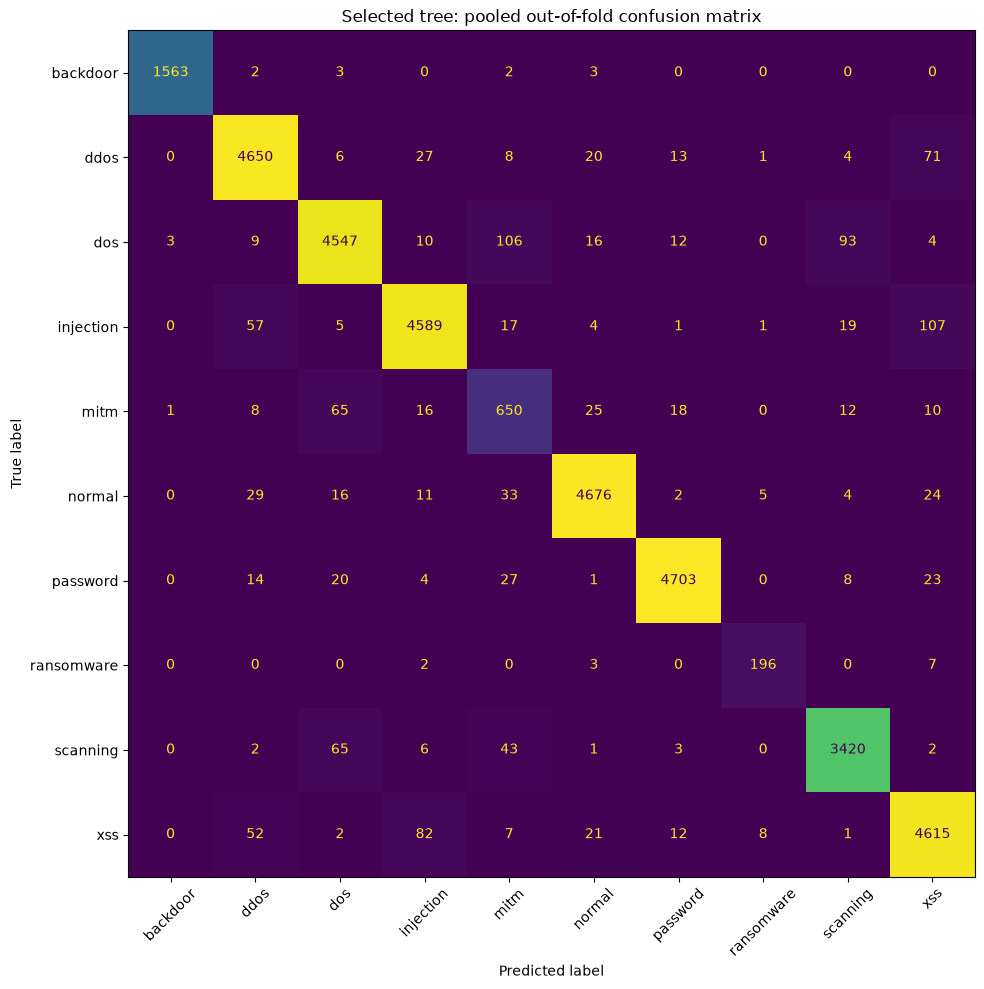

In [12]:
CLASS_CODES = sorted(CLASS_NAMES)
class_names = []
for class_code in CLASS_CODES:
    class_names.append(CLASS_NAMES[class_code])

report = metrics.classification_report(
    y, oof_prediction, labels=CLASS_CODES, target_names=class_names,
    output_dict=True, zero_division=0,
)
class_report = pd.DataFrame(report).T.loc[class_names]
print("Per-class metrics from pooled out-of-fold predictions:")
print(class_report.round(4).to_string())
print("Pooled OOF accuracy:", round(metrics.accuracy_score(y, oof_prediction), 6))
print("Pooled OOF macro F1:",
      round(metrics.f1_score(y, oof_prediction, average="macro"), 6))

cm = metrics.confusion_matrix(y, oof_prediction, labels=CLASS_CODES)
assert cm.sum() == len(y)
assert np.array_equal(cm.sum(axis=1), class_report["support"].to_numpy())
print("Rows = true class; columns = predicted class")
print(pd.DataFrame(cm, index=class_names, columns=class_names).to_string())
fig, ax = plt.subplots(figsize=(12, 10))
display = metrics.ConfusionMatrixDisplay(cm, display_labels=class_names)
display.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title("Selected tree: pooled out-of-fold confusion matrix")
fig.tight_layout()
plt.show()

**Interpretation.** The search selects `criterion="entropy"`,
`max_depth=20`, `min_samples_leaf=1` and `ccp_alpha=0.0001`. Mean validation macro
F1 is **0.9457**, ranging from 0.9415 to 0.9499 across folds, with a range of
0.0083. Mean weighted F1 is 0.9625 and mean accuracy is 0.9622. The higher weighted
F1 shows that the larger classes have better results overall than the classes
given equal weight by macro F1.

The weakest class is `mitm`, with pooled F1 0.7656 and recall 0.8075 on 805 rows.
The rarest class, `ransomware`, has F1 0.9356 on 208 rows. Its score is good here,
but it is based on fewer examples. These class scores and the confusion matrix
use validation predictions only. Pooling predictions and averaging fold scores
are different calculations, so their macro F1 values need not match exactly.

The tree refitted on all development rows has 1235 nodes, depth 20 and 618 leaves.
These describe that fit, not the separate fold models. Individual paths can be
read, but the whole tree is too large to explain as a short list of rules.

**Execution environment.** The versions used for this run are printed above.
They come from the available Anaconda environment and differ from the versions
in `requirements.txt`. The team should agree on the environment for the final
run, since small version differences can affect the results.

# P4.2 — The complexity study

For each curve, we change one hyperparameter and keep the others at
their selected values. Both lines show macro F1 averaged over the same canonical
folds, with preprocessing fitted inside each training fold. These curves help us
understand complexity; they do not start a new hyperparameter search.

For the selected configuration, mean training F1 is 0.9797 and mean validation
F1 is 0.9457. The gap shows that the model fits training rows more closely than
unseen rows. We use training scores only as a diagnostic in this section.

In [13]:
# Training scores are used here only to diagnose model complexity.
print("Selected mean training macro F1:",
      round(search.cv_results_["mean_train_score"][best_index], 6))
print("Selected mean validation macro F1:", round(search.best_score_, 6))

columns = ["rank_test_score", "param_tree__max_depth", "param_tree__min_samples_leaf",
           "param_tree__ccp_alpha", "param_tree__criterion", "mean_train_score",
           "mean_test_score", "mean_fit_time"]
print(grid_results.sort_values("rank_test_score")[columns].head(10).to_string(index=False))

Selected mean training macro F1: 0.979723
Selected mean validation macro F1: 0.945742
 rank_test_score param_tree__max_depth  param_tree__min_samples_leaf  param_tree__ccp_alpha param_tree__criterion  mean_train_score  mean_test_score  mean_fit_time
               1                    20                             1                0.00010               entropy          0.979723         0.945742       0.191371
               2                  None                             1                0.00010                  gini          0.959624         0.945610       0.146249
               3                  None                             1                0.00010               entropy          0.981368         0.945453       0.181299
               4                    20                             1                0.00010                  gini          0.959004         0.944962       0.145091
               5                    20                             1                0.00000   

In [14]:
curve_values = {
    "tree__max_depth": [2, 3, 5, 8, 12, 20, None],
    "tree__ccp_alpha": [0.0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
}
curve_tables = {}
for parameter, values in curve_values.items():
    curve_model = make_tree()
    curve_model.set_params(**best)
    train_scores, val_scores = validation_curve(
        curve_model, X, y, param_name=parameter, param_range=values,
        cv=folds, scoring="f1_macro", n_jobs=4, error_score="raise",
    )
    curve_table = pd.DataFrame({
        "value": values,
        "train_mean": train_scores.mean(axis=1),
        "validation_mean": val_scores.mean(axis=1),
        "train_range": np.ptp(train_scores, axis=1),
        "validation_range": np.ptp(val_scores, axis=1),
    })
    curve_tables[parameter] = curve_table
    print(parameter)
    print(curve_table.round(6).to_string(index=False))

tree__max_depth
 value  train_mean  validation_mean  train_range  validation_range
   2.0    0.253483         0.253047     0.010951          0.012974
   3.0    0.456857         0.456128     0.000551          0.003251
   5.0    0.716737         0.716002     0.074710          0.080043
   8.0    0.927677         0.925357     0.019427          0.022583
  12.0    0.961800         0.943780     0.012288          0.010241
  20.0    0.979723         0.945742     0.002162          0.008317
   NaN    0.981368         0.945453     0.002824          0.011465


tree__ccp_alpha
   value  train_mean  validation_mean  train_range  validation_range
0.000000    0.991636         0.944165     0.006367          0.010708
0.000001    0.991636         0.944165     0.006367          0.010708
0.000010    0.991636         0.944165     0.006367          0.010708
0.000100    0.979723         0.945742     0.002162          0.008317
0.001000    0.939037         0.933325     0.007298          0.010261
0.010000    0.885749         0.884049     0.030927          0.024637
0.100000    0.432560         0.431605     0.009781          0.009468


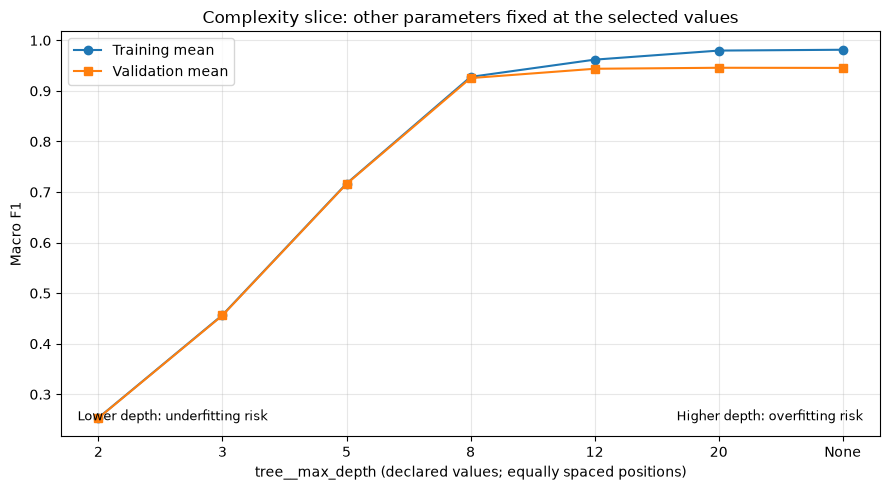

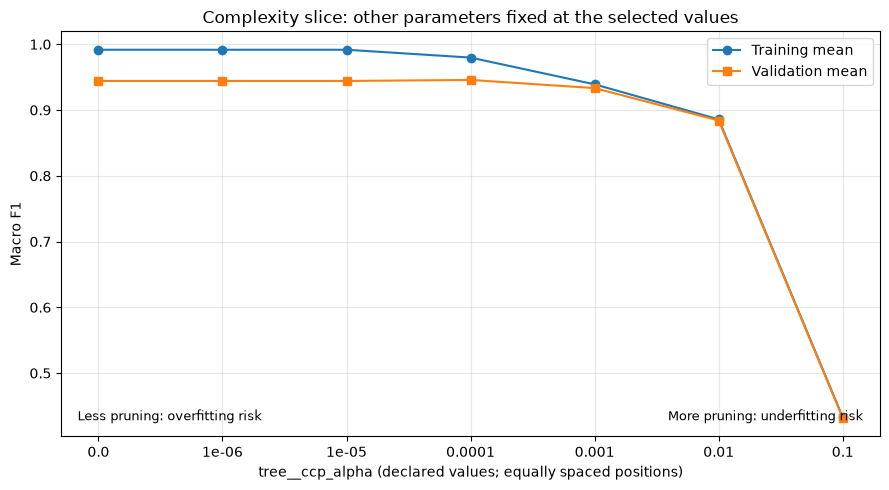

In [15]:
for parameter, values in curve_values.items():
    curve_table = curve_tables[parameter]
    positions = np.arange(len(values))
    labels = []
    for value in values:
        labels.append(str(value))
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(positions, curve_table["train_mean"], "o-", label="Training mean")
    ax.plot(positions, curve_table["validation_mean"], "s-", label="Validation mean")
    ax.set_xticks(positions, labels)
    ax.set_xlabel(parameter + " (declared values; equally spaced positions)")
    ax.set_ylabel("Macro F1")
    ax.set_title("Complexity slice: other parameters fixed at the selected values")
    if parameter == "tree__max_depth":
        left_label = "Lower depth: underfitting risk"
        right_label = "Higher depth: overfitting risk"
    else:
        left_label = "Less pruning: overfitting risk"
        right_label = "More pruning: underfitting risk"
    ax.text(0.02, 0.04, left_label, transform=ax.transAxes, fontsize=9)
    ax.text(0.98, 0.04, right_label, transform=ax.transAxes, ha="right", fontsize=9)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

**Reading of the curves.**

- **Depth:** on the left, depth 2 gives training F1 0.2535 and validation F1
  0.2530. Both are low, so the tree is too simple and underfits. On the right,
  unlimited depth gives training F1 0.9814 and validation F1 0.9455. Training keeps
  improving more than validation, so this side has more risk of overfitting.
- **Pruning:** the direction is reversed. On the left, alpha 0 gives training
  F1 0.9916 and validation F1 0.9442, leaving a clear gap. On the right, alpha
  0.1 reduces them to 0.4326 and 0.4316. This strong pruning removes useful splits
  and underfits. A small gap is therefore not enough: both scores can be poor.

The other settings stay fixed in each curve. These results do not mean that every
deep tree overfits or that pruning always helps. The ranges in the tables describe
variation across folds; they are not confidence intervals.

Path fold: 0 | training rows: 27942
Criterion: entropy
Path settings: max_depth=None, min_samples_leaf=1, ccp_alpha=0
Number of alpha entries: 778
Number of distinct alphas: 544
Alpha minimum: 0.0
Alpha maximum: 0.49966778700307346
   ccp_alpha  total_leaf_impurity
0.000000e+00             0.002712
0.000000e+00             0.002712
0.000000e+00             0.002712
0.000000e+00             0.002712
2.710505e-20             0.002712
 ccp_alpha  total_leaf_impurity
  0.146731             1.752672
  0.147329             1.900001
  0.293013             2.193014
  0.373804             2.566818
  0.499668             3.066486


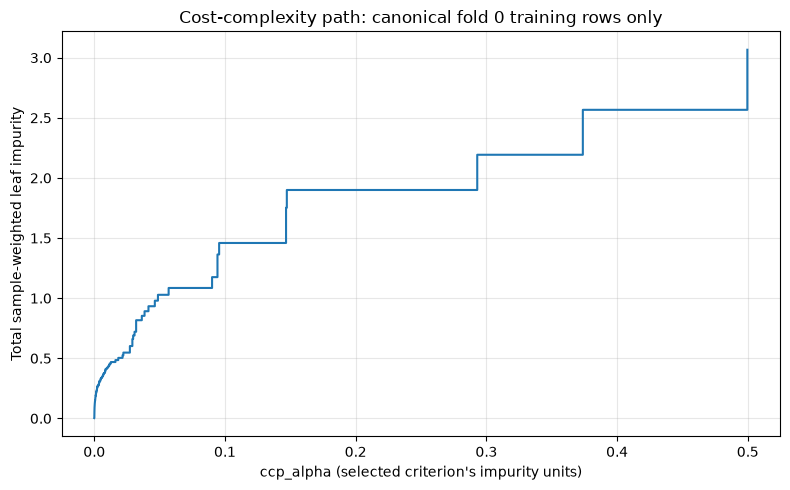

In [16]:
# A maximal tree's path on the TRAINING portion of canonical fold 0 only.
path_fold = 0
train_idx, val_idx = folds[path_fold]
path_preprocessor = make_preprocessor()
X_train_t = path_preprocessor.fit_transform(X.iloc[train_idx])
path_tree = DecisionTreeClassifier(
    criterion=best["tree__criterion"], random_state=PROJECT_RANDOM_STATE,
)
path = path_tree.cost_complexity_pruning_path(X_train_t, y.iloc[train_idx])
path_table = pd.DataFrame({"ccp_alpha": path.ccp_alphas,
                           "total_leaf_impurity": path.impurities})
assert np.all(np.diff(path.ccp_alphas) >= -1e-12)
assert np.all(np.diff(path.impurities) >= -1e-12)
print("Path fold:", path_fold, "| training rows:", len(train_idx))
print("Criterion:", best["tree__criterion"])
print("Path settings: max_depth=None, min_samples_leaf=1, ccp_alpha=0")
print("Number of alpha entries:", len(path_table))
print("Number of distinct alphas:", len(np.unique(path.ccp_alphas)))
print("Alpha minimum:", path.ccp_alphas.min())
print("Alpha maximum:", path.ccp_alphas.max())
print(path_table.head().to_string(index=False))
print(path_table.tail().to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5))
ax.step(path.ccp_alphas, path.impurities, where="post")
ax.set_xlabel("ccp_alpha (selected criterion's impurity units)")
ax.set_ylabel("Total sample-weighted leaf impurity")
ax.set_title("Cost-complexity path: canonical fold 0 training rows only")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**What the pruning path shows.** We use only the training rows of fold 0
and grow an unrestricted tree with the selected entropy criterion. Its path has
778 alpha entries, including repeated values, and 544 distinct values. The range
is from 0 to 0.499668. Increasing alpha removes subtrees and increases training
leaf impurity; the last step leaves only the root.

Here alpha is measured in entropy units. It cannot be read as the same amount of
pruning as an alpha from a squared-error regression tree. As explained in Topic 8,
scikit-learn uses weighted leaf impurity for pruning, rather than classification
error. The path gives candidate alphas and shows how pruning works; it does not
choose the best one. Our model is selected using validation macro F1.

# P4.4 — What a tree importance says

In [17]:
# The selected tree refitted on all development rows, as in the size description.
print("Importances from best_estimator_, fitted on", t.n_node_samples[0], "rows")
importance_rows = []
for column in FEATURES:
    total = 0.0
    for position, name in enumerate(feature_names):
        if column in NOMINAL:
            belongs = name.startswith("cat__" + column + "_")
        else:
            belongs = name == "num__" + column
        if belongs:
            total = total + final_tree.feature_importances_[position]
    importance_rows.append({"predictor": column, "importance": total})

importances = pd.DataFrame(importance_rows)
importances = importances.sort_values("importance", ascending=False)
assert np.isclose(importances["importance"].sum(), 1.0)
print(importances.round(6).to_string(index=False))
print("Importance sum:", importances["importance"].sum())

Importances from best_estimator_, fitted on 34928 rows
   predictor  importance
     service    0.194533
src_ip_bytes    0.178085
  conn_state    0.158459
   src_bytes    0.116035
   dst_bytes    0.087332
    src_pkts    0.085042
dst_ip_bytes    0.073043
    duration    0.066432
    dst_pkts    0.023531
       proto    0.015562
missed_bytes    0.001946
Importance sum: 1.0


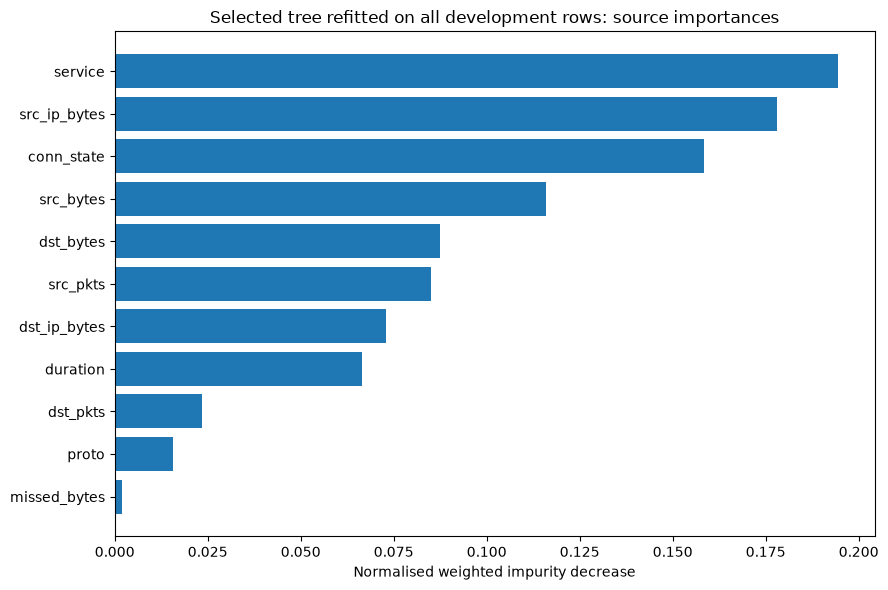

In [18]:
plot_importances = importances.sort_values("importance")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_importances["predictor"], plot_importances["importance"])
ax.set_xlabel("Normalised weighted impurity decrease")
ax.set_title("Selected tree refitted on all development rows: source importances")
fig.tight_layout()
plt.show()

**What a tree importance means.** It is the share of the total weighted
impurity decrease due to splits on that predictor. It is calculated on the
training rows of the stated fit, across the whole tree and all classes. There is
one importance per predictor, not one per class, and the shares sum to one.

We use the selected tree refitted on all development rows and sum each nominal
predictor's one-hot columns. The largest source importances are `service`
(0.1945), `src_ip_bytes` (0.1781) and `conn_state` (0.1585).

**What a tree importance does not say.** It has no sign: it does not tell us which
class a predictor pushes towards, whether larger values favour an attack, or how
much a prediction would change if the predictor changed. It is not a measure of
performance on new rows or evidence of a causal effect. Correlated predictors
can share importance, and predictors with more possible splits can be favoured.

# P4.5 — Challenge A against Practice 3 and Practice 2

In [19]:
# R4's reader, with a check that exactly one historical row matches.
def previous_scores(milestone, challenge, family):
    table = pd.read_csv("../comparativa.csv")
    row = table[(table["milestone"] == milestone)
                & (table["challenge"] == challenge)
                & (table["family"] == family)]
    assert len(row) == 1
    text = row["primary_metric_per_fold"].iloc[0]
    scores = np.array(text.split(), dtype=float)
    assert len(scores) == len(folds)
    return scores

p3_cyber = previous_scores("P3", "cyber", "LogisticRegression")
p2_cyber = previous_scores("P2", "cyber", "KNN")
# Historical scores have four decimals: compare at their stored precision.
tree_comparison = np.round(tree_cyber, 4)
paired = pd.DataFrame({"fold": np.arange(len(folds)), "tree": tree_comparison,
                       "P3_logistic": p3_cyber, "P2_KNN": p2_cyber})
paired["tree_minus_P3"] = tree_comparison - p3_cyber
paired["tree_minus_P2"] = tree_comparison - p2_cyber
print(paired.round(4).to_string(index=False))
for column in ["tree_minus_P3", "tree_minus_P2"]:
    delta = paired[column].to_numpy()
    print(column, "| mean:", round(delta.mean(), 4),
          "| range:", round(spread(delta), 4),
          "| minimum:", round(delta.min(), 4), "| maximum:", round(delta.max(), 4),
          "| positive folds:", int((delta > 0).sum()))

 fold   tree  P3_logistic  P2_KNN  tree_minus_P3  tree_minus_P2
    0 0.9453       0.8407  0.9436         0.1046         0.0017
    1 0.9496       0.8332  0.9473         0.1164         0.0023
    2 0.9499       0.8453  0.9490         0.1046         0.0009
    3 0.9415       0.8353  0.9428         0.1062        -0.0013
    4 0.9423       0.8361  0.9451         0.1062        -0.0028
tree_minus_P3 | mean: 0.1076 | range: 0.0118 | minimum: 0.1046 | maximum: 0.1164 | positive folds: 5
tree_minus_P2 | mean: 0.0002 | range: 0.0051 | minimum: -0.0028 | maximum: 0.0023 | positive folds: 3


In [20]:
# Historical fit times are snapshots, not a controlled timing benchmark.
comparison_table = pd.read_csv("../comparativa.csv")
cyber_history = comparison_table[comparison_table["challenge"] == "cyber"]
print(cyber_history[["milestone", "family", "route", "primary_metric",
                     "primary_metric_spread", "fit_time_s"]].to_string(index=False))
print("Current tree search time (s):", round(search_seconds, 3))
print("Current tree mean single-pipeline fit time (s):",
      round(fold_metrics["fit_time_s"].mean(), 6))
print("Current selected-tree leaves:", final_tree.get_n_leaves())

dummy_cyber = previous_scores("P2", "cyber", "Dummy").mean()
dummy_storage = previous_scores("P2", "storage", "Dummy").mean()
gap_rows = []
for milestone, cyber_scores, storage_family in [
    ("P2", p2_cyber, "KNN"), ("P3", p3_cyber, "LinearRegression"),
]:
    storage_scores = previous_scores(milestone, "storage", storage_family)
    gap_rows.append({"milestone": milestone,
                     "cyber_gap_closed": (cyber_scores.mean() - dummy_cyber)
                                         / (1 - dummy_cyber),
                     "storage_dummy_MAE_removed": 1 - storage_scores.mean() / dummy_storage})
print("Relative-to-Dummy summaries (different tasks, not a common difficulty scale):")
print(pd.DataFrame(gap_rows).round(4).to_string(index=False))
print("P4 cyber gap closed:",
      round((tree_cyber.mean() - dummy_cyber) / (1 - dummy_cyber), 4))

milestone             family   route  primary_metric  primary_metric_spread  fit_time_s
       P2              Dummy primary          0.0242                 0.0000      0.0057
       P2                KNN primary          0.9456                 0.0062      0.0348
       P3 LogisticRegression primary          0.8381                 0.0121      7.6659
Current tree search time (s): 53.611
Current tree mean single-pipeline fit time (s): 0.152849
Current selected-tree leaves: 618
Relative-to-Dummy summaries (different tasks, not a common difficulty scale):
milestone  cyber_gap_closed  storage_dummy_MAE_removed
       P2            0.9442                     0.7341
       P3            0.8341                     0.7073
P4 cyber gap closed: 0.9444


### Storage results used for context

The storage scores below come from R3's executed draft at
`notebooks/borradores/R3_p4_storage.ipynb`, commit `7f79f315` on `r3-storage`.
They are a saved snapshot, not a regression experiment carried out in R2.

The latest checked role notebook, commit `1f8f94f`, still has no executed
results. We therefore keep this comparison provisional until R3/R4 confirm the
storage scores for the final submission.

In [21]:
# R3's saved draft output, rounded to the four decimals it prints.
r3_draft_storage = np.array([0.1238, 0.1286, 0.1319, 0.1353, 0.1332])
print("R3 draft storage MAE(z), folds 0 to 4:", r3_draft_storage)
print("R3 draft storage mean MAE(z):", round(r3_draft_storage.mean(), 4))
print("R3 draft share of Dummy MAE removed:",
      round(1 - r3_draft_storage.mean() / dummy_storage, 4))
print("Cyber share of gap to perfect F1 closed:",
      round((tree_cyber.mean() - dummy_cyber) / (1 - dummy_cyber), 4))

R3 draft storage MAE(z), folds 0 to 4: [0.1238 0.1286 0.1319 0.1353 0.1332]
R3 draft storage mean MAE(z): 0.1306
R3 draft share of Dummy MAE removed: 0.8071
Cyber share of gap to perfect F1 closed: 0.9444


### The six fixed comparison questions

1. **Size and consistency of the change.** Against P3 logistic regression, the
   tree improves macro F1 on all five folds. The mean difference is +0.1076, from
   +0.1046 to +0.1164, with a range of 0.0118. This improvement is much larger than
   the fold ranges of the tree (0.0083) and logistic regression (0.0121), so the
   change is large and consistent in these folds.

   Against P2 KNN, the mean difference is only +0.0002. The tree wins in three
   folds and loses in two; differences go from -0.0028 to +0.0023, with a range
   of 0.0051. The mean change is much smaller than the fold ranges of the tree
   (0.0083) and KNN (0.0062), so there is no clear practical improvement here.
   These are descriptive comparisons, not statistical tests. We compare at
   the four-decimal precision of the historical scores. Both the tree and KNN
   were tuned on these folds, so their selected scores may be optimistic.

2. **Route and representation.** All three models use the primary route, the same
   source predictors and the same canonical folds. P3 drops `proto=tcp`,
   `service=-` and `conn_state=SF`, and standardises the log-transformed numeric
   values. P2 KNN keeps all one-hot levels but also uses `log1p` and scaling.
   Our tree keeps every level and uses raw numeric values.

   Both comparisons are therefore pipeline comparisons. Scaling adds no useful
   split options to a tree, but it changes the distances used by KNN. The results
   compare these particular pipelines; they do not prove that one model family
   is always better than another.

3. **What can the new family express?** Unlike the additive class scores of the
   logistic model, a tree can use different conditions in different parts of the
   data and combine predictors along a path. This gives nonlinear boundaries and
   interactions. KNN can also produce nonlinear boundaries, so the tree is not
   automatically more expressive than KNN. The main difference is that it uses
   threshold rules instead of neighbour votes.

4. **What did it cost?** The search tried 192 configurations, requiring 960 fold
   fits, and took 53.611 seconds including the final refit. A selected pipeline
   fit took 0.152849 seconds on average. Historical fit times are printed above,
   but they were measured in separate runs, so they are only rough references.
   This search takes more tuning than P3's fixed logistic model and tries more
   settings than P2's neighbour-count search. A tree path is readable, but 618
   leaves make the whole tree difficult to explain. Logistic regression offers
   coefficients and KNN offers neighbours as different ways to inspect a result.

5. **Did the ordering of the challenges' difficulty change?** We cannot compare
   cyber F1 directly with storage MAE because they measure different things.
   Relative to each Dummy baseline, cyber closes more of its gap to perfect F1
   than storage removes of its Dummy MAE in P2 and P3. Using R3's draft, the same
   pattern remains in P4: the printed shares are 0.9444 for cyber and 0.8071 for
   storage. This suggests no reversal under this comparison, but it is not a
   common difficulty scale. The tree can help with nonlinear patterns in both
   tasks, while storage still has to predict latency for unseen configurations.
   This answer remains provisional until R3/R4 confirm the storage results.

6. **Would you ship the new model?** I would keep both the tree and KNN as
   candidates. The tree clearly improves on the P3 logistic model on these folds,
   but its small average advantage over KNN is not enough to justify replacing
   KNN. I would first check performance on independent data under the course
   protocol, errors on costly attack classes, prediction time and memory use.
   Better operational results, or a simpler tree with similar performance, could
   make me choose it. The development scores alone do not settle that decision.

## R2 handoff and AI assistance

The printed fold scores and summary below are ready for R4's comparison-table
row. R5 can integrate the R2 sections with the shared setup and keep the saved
figures. This notebook does not change the cumulative CSV or other roles' files.

**AI assistance declaration for R5:** Codex helped write and revise the code and
explanations for P4.1, P4.2, the importance part of P4.4 and P4.5. The work was
checked using a fresh-kernel run, group and validation-coverage checks, agreement
with the grid-search scores, and inspection of the saved figures and output.
The explanations were then reviewed against the official Practice 4 handout.
Marina should review every part before submission and be able to explain it
without assistance.

In [22]:
# R2-owned handoff: printed only; R4 owns the cumulative CSV.
r2_handoff = {
    "milestone": "P4", "challenge": "cyber", "family": "DecisionTreeClassifier",
    "route": "primary", "configuration": best,
    "preprocessing": "full one-hot; unscaled raw numeric values; in-fold Pipeline",
    "features": "11 source predictors; unchanged predictive-information basis",
    "validation": "five canonical grouped folds from folds/cyber_folds.csv",
    "primary_metric_per_fold": tree_cyber.tolist(),
    "primary_metric": float(tree_cyber.mean()),
    "primary_metric_spread": float(spread(tree_cyber)),
    "weighted_f1": float(fold_metrics["weighted_f1"].mean()),
    "accuracy": float(fold_metrics["accuracy"].mean()),
    "fit_time_s": float(fold_metrics["fit_time_s"].mean()),
    "search_time_s": search_seconds,
    "nodes": int(t.node_count), "depth": int(final_tree.get_depth()),
    "leaves": int(final_tree.get_n_leaves()),
}
print(json.dumps(r2_handoff, indent=2))

{
  "milestone": "P4",
  "challenge": "cyber",
  "family": "DecisionTreeClassifier",
  "route": "primary",
  "configuration": {
    "tree__ccp_alpha": 0.0001,
    "tree__criterion": "entropy",
    "tree__max_depth": 20,
    "tree__min_samples_leaf": 1
  },
  "preprocessing": "full one-hot; unscaled raw numeric values; in-fold Pipeline",
  "features": "11 source predictors; unchanged predictive-information basis",
  "validation": "five canonical grouped folds from folds/cyber_folds.csv",
  "primary_metric_per_fold": [
    0.9453236313444494,
    0.9496397360874452,
    0.9498627593112585,
    0.9415456918878636,
    0.9423366873453627
  ],
  "primary_metric": 0.9457417011952758,
  "primary_metric_spread": 0.008317067423394886,
  "weighted_f1": 0.9625020115173963,
  "accuracy": 0.9622366442671619,
  "fit_time_s": 0.15284882000414654,
  "search_time_s": 53.611182900029235,
  "nodes": 1235,
  "depth": 20,
  "leaves": 618
}
